# YOLO v8 써보기 - 테스트 노트북

실행 전 준비 (터미널에서, 처음 한 번만):

```bash
python3 -m venv yolov8
source yolov8/bin/activate
pip install ultralytics ipykernel
python -m ipykernel install --user --name yolov8 --display-name "yolov8"
```

Jupyter 오른쪽 위 커널을 **yolov8**로 선택한 뒤 위에서부터 순서대로 실행하세요.

## 1. 모델 불러오기
처음 실행하면 `yolov8n.pt`가 자동으로 다운로드됩니다.

In [10]:
from ultralytics import YOLO
print("import 완료")

import 완료


In [11]:
# Create a new YOLO model from scratch
# model = YOLO("yolov8n.yaml")

# Load a pretrained YOLO model (recommended for training)
model = YOLO("yolov8n.pt")
print("모델 로드 완료")

모델 로드 완료


## 2. 학습 (train)
coco8 데이터셋이 자동으로 다운로드된 뒤 3 에폭 학습합니다. 결과는 `runs/detect/train` 폴더에 저장됩니다.

In [12]:
# Train the model using the 'coco8.yaml' dataset for 3 epochs
results = model.train(data="coco8.yaml", epochs=3)

# 이번 학습 결과가 저장된 폴더 (train, train2, ... 중 실제 경로)
train_dir = results.save_dir
print("학습 결과 폴더:", train_dir)

Ultralytics 8.4.208 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7806MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, op

## 3. 평가 (val)
검증 데이터로 성능을 평가합니다.

In [13]:
# Evaluate the model's performance on the validation set
metrics = model.val()

Ultralytics 8.4.208 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7806MiB)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3702.2±745.7 MB/s, size: 54.0 KB)
val: Scanning /home/gtp/robostar_ws/yolo_ws/source/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 32.9it/s 0.0s
                   all          4         17       0.62      0.889      0.897      0.615
                person          3         10      0.676        0.5      0.572      0.289
                   dog          1          1      0.361          1      0.995      0.597
                 horse          1          2      0.725          1      0.995      0.596
              elephant          1          2      0.611      0.834      0.828      0.319

## 4. 이미지로 예측해 보기

In [14]:
# Perform object detection on an image using the model
results = model("https://ultralytics.com/images/bus.jpg")


image 1/1 /home/gtp/robostar_ws/yolo_ws/source/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 2.9ms
Speed: 2.1ms preprocess, 2.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 480)


## 5. ONNX 형식으로 변환 (export)
`onnx` 패키지가 없으면 자동 설치됩니다. 설치 후 오류가 나면 커널을 재시작하고 1번부터 다시 실행하세요.

In [15]:
# Export the model to ONNX format
success = model.export(format="onnx")
print(success)

Ultralytics 8.4.208 🚀 Python-3.12.3 torch-2.15.0+cu132 CPU (Intel Core i7-14700HX)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/home/gtp/robostar_ws/yolo_ws/source/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 0.4s, saved as '/home/gtp/robostar_ws/yolo_ws/source/runs/detect/train/weights/best.onnx' (12.3 MB)

Export complete (0.5s)
Results saved to /home/gtp/robostar_ws/yolo_ws/source/runs/detect/train/weights/best.onnx
Predict:         yolo predict task=detect model=/home/gtp/robostar_ws/yolo_ws/source/runs/detect/train/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/home/gtp/robostar_ws/yolo_ws/source/runs/detect/train/weights/best.onnx imgsz=640 data=/home/gtp/robostar_ws/yolo_ws/yolov8/lib/python3.12/site-packages/

## 6. 학습한 모델(best.pt)로 detect 확인 (3-4)
2번에서 확인한 학습 결과 폴더의 `best.pt`를 불러옵니다. 원본 `yolov8n.pt`가 아니라 직접 학습한 모델이에요.

In [16]:
from pathlib import Path

best_path = Path(train_dir) / "weights" / "best.pt"
# 커널을 재시작해서 train_dir이 없다면 직접 경로를 적으세요. 예:
# best_path = "runs/detect/train/weights/best.pt"

trained_model = YOLO(best_path)
results = trained_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,  # 확신도 25% 이상인 객체만 표시
)

# 검출된 객체 목록 출력
r = results[0]
for box in r.boxes:
    print(r.names[int(box.cls)], round(float(box.conf), 2))


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /home/gtp/robostar_ws/yolo_ws/source/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 2.9ms
Speed: 0.9ms preprocess, 2.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 480)
bus 0.88
person 0.87
person 0.85
person 0.82
person 0.27
stop sign 0.25


## 7. 결과를 이미지로 저장하고 보기 (3-5)

In [17]:
results = trained_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    save=True,  # 검출 결과가 그려진 이미지를 저장
)
save_dir = results[0].save_dir
print("저장 위치:", save_dir)


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /home/gtp/robostar_ws/yolo_ws/source/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 3.1ms
Speed: 1.3ms preprocess, 3.1ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /home/gtp/robostar_ws/yolo_ws/source/runs/detect/predict
저장 위치: /home/gtp/robostar_ws/yolo_ws/source/runs/detect/predict


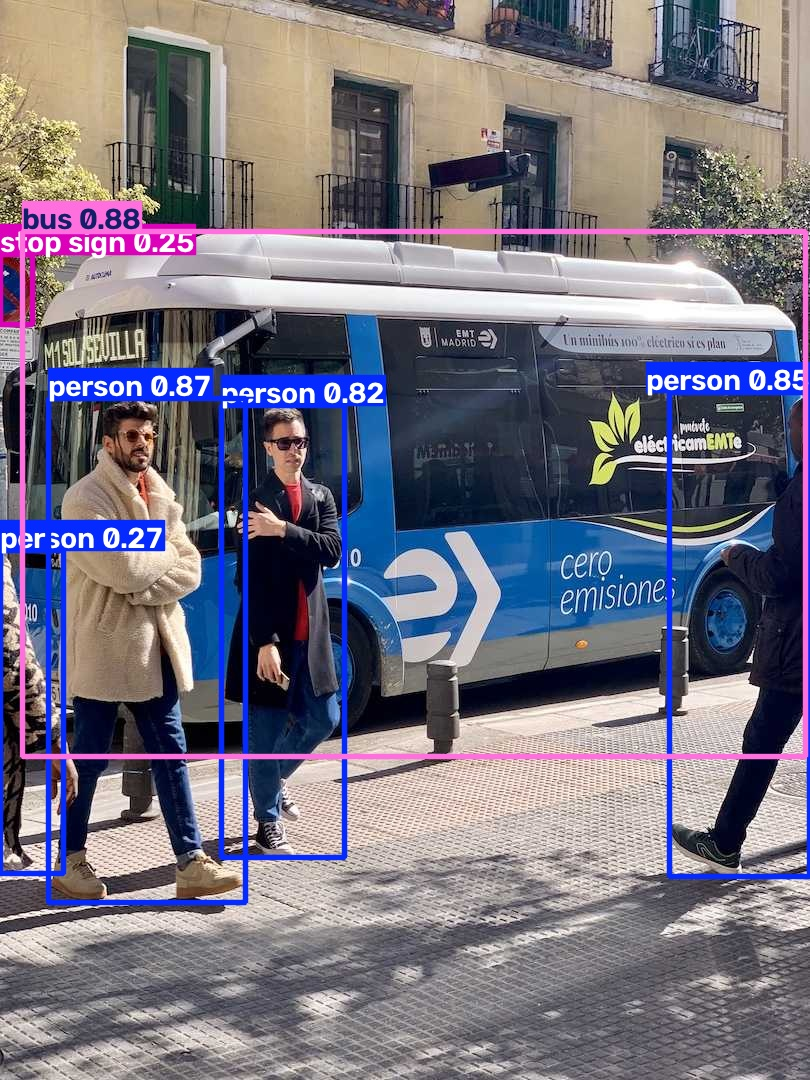

In [18]:
# 저장된 결과 이미지를 노트북 안에서 바로 보기
from IPython.display import Image, display

display(Image(filename=str(Path(save_dir) / "bus.jpg"), width=500))